# Modelado y evaluación

En esta notebook se desarrollan y comparan modelos de regresión para predecir la cantidad de pasajeros de vuelos regulares de cabotaje en Argentina durante 2025.

La predicción se plantea 24 horas antes de la salida del vuelo. Para esta primera versión se utilizan como variables predictoras el aeropuerto de salida, el destino y la aerolínea.

El conjunto utilizado corresponde al dataset procesado durante la etapa de preparación de datos.

In [7]:
import pandas as pd

df = pd.read_csv("../data/processed/vuelos_regulares_cabotaje_2025_procesado.csv")

In [8]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

df.head()

Filas: 132838
Columnas: 7


,Fecha UTC,Hora UTC,Aeropuerto,Origen / Destino,Aerolinea Nombre,Aeronave,Pasajeros
0,01/01/2025,0:09,IGU,EZE,AEROLINEAS ARGENTINAS SA,BO-737-8BK,83.0
1,01/01/2025,0:12,DOZ,AER,JETSMART AIRLINES S.A.,AIB-A320-232,23.0
2,01/01/2025,0:20,BAR,EZE,FB LÍNEAS AÉREAS - FLYBONDI,BO-737-8Q8,103.0
3,01/01/2025,0:29,IGU,EZE,FB LÍNEAS AÉREAS - FLYBONDI,BO-737-8Q8,104.0
4,01/01/2025,0:44,BAR,EZE,FB LÍNEAS AÉREAS - FLYBONDI,BO-737-8Q8,103.0


## Origen de los datos

Los datos utilizados provienen del dataset **“Aterrizajes y despegues procesados por la Administración Nacional de Aviación Civil”**, publicado por la ANAC a través del portal de Datos Abiertos de la Secretaría de Transporte.

El archivo original tenía 597.784 registros y 12 columnas. Durante la preparación se seleccionaron los vuelos regulares de cabotaje, se trabajó solamente con los registros de despegue y se eliminaron los duplicados exactos.

De esta forma, cada fila del conjunto preparado representa un registro de despegue correspondiente a una operación regular de cabotaje.

También se descartó la variable `PAX` porque contiene información derivada directamente de `Pasajeros`, por lo que utilizarla como predictor generaría fuga de información.

Después de esta preparación, el conjunto utilizado para el modelado quedó formado por 132.838 registros y 7 columnas.

El análisis y la preparación completa de los datos se encuentran documentados en la notebook `preparacion_datos_anac_2025.ipynb`.

## Resumen del análisis exploratorio

Antes de comenzar con el modelado se realizó un análisis exploratorio sobre el conjunto preparado.

La variable `Pasajeros` tiene una media de 129,79 pasajeros y una mediana de 140. Los valores van desde 0 hasta 284 pasajeros.

También se encontraron 1.824 operaciones con 0 pasajeros, que representan aproximadamente el 1,37 % del conjunto. Estos registros se mantuvieron porque no hay evidencia suficiente para considerarlos errores.

En cuanto a las variables predictoras, el conjunto contiene 42 aeropuertos de salida, 66 destinos y 41 aerolíneas. Al combinar aeropuerto de salida y destino se obtienen 420 rutas diferentes.


### Distribución de pasajeros

Para ver cómo se distribuye la variable que queremos predecir, se muestra la cantidad de operaciones según el número de pasajeros registrados.

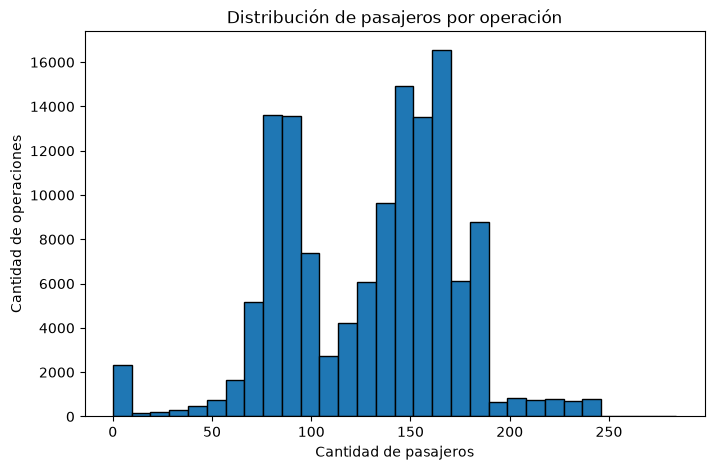

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df["Pasajeros"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Cantidad de pasajeros")
plt.ylabel("Cantidad de operaciones")
plt.title("Distribución de pasajeros por operación")

plt.show()

### Lectura de la distribución

La mayor parte de las operaciones se concentra aproximadamente entre 70 y 190 pasajeros.

También aparecen algunos casos con 0 pasajeros y un grupo mucho más chico de operaciones con valores superiores a 200.

La distribución no se concentra alrededor de un único valor, lo que muestra que la cantidad de pasajeros cambia bastante entre operaciones.

### Aerolíneas con más operaciones

Para complementar el análisis exploratorio, se revisa qué aerolíneas concentran la mayor cantidad de operaciones dentro del conjunto utilizado.

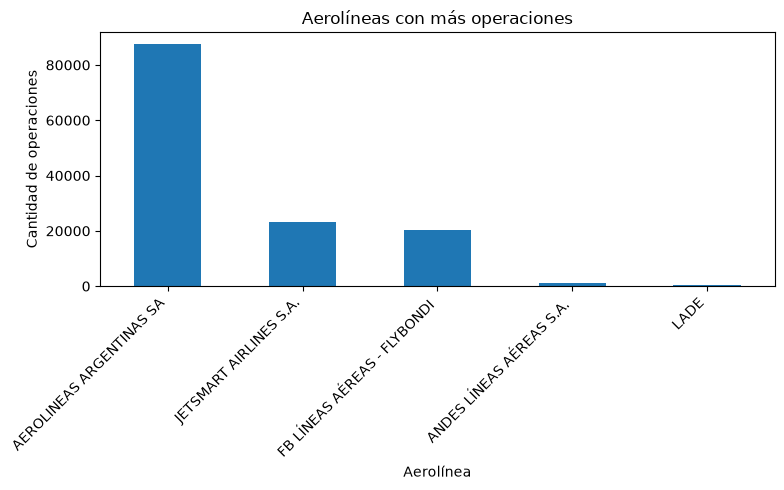

In [10]:
top_aerolineas = df["Aerolinea Nombre"].value_counts().head(5)

plt.figure(figsize=(8, 5))

top_aerolineas.plot(kind="bar")

plt.xlabel("Aerolínea")
plt.ylabel("Cantidad de operaciones")
plt.title("Aerolíneas con más operaciones")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

### Lectura del gráfico

Aerolíneas Argentinas concentra claramente la mayor cantidad de operaciones del conjunto. Bastante más atrás aparecen JetSMART y Flybondi, mientras que el resto de las aerolíneas tiene una participación mucho menor.

Esto muestra que el conjunto no está distribuido de manera pareja entre todas las aerolíneas.

## Preparación temporal de los datos

Como el objetivo es evaluar el modelo sobre operaciones futuras, los registros se van a organizar respetando el orden temporal.

Primero se convierte la variable `Fecha UTC` a formato de fecha para poder ordenar correctamente las observaciones.

In [11]:
df["Fecha UTC"] = pd.to_datetime(
    df["Fecha UTC"],
    format="%d/%m/%Y"
)

df["Fecha UTC"].agg(["min", "max"])

min   2025-01-01
max   2025-12-31
Name: Fecha UTC, dtype: datetime64[us]

In [12]:
df = df.sort_values("Fecha UTC").reset_index(drop=True)

df[["Fecha UTC", "Aeropuerto", "Origen / Destino", "Aerolinea Nombre", "Pasajeros"]].head()

,Fecha UTC,Aeropuerto,Origen / Destino,Aerolinea Nombre,Pasajeros
0,2025-01-01,IGU,EZE,AEROLINEAS ARGENTINAS SA,83.0
1,2025-01-01,EZE,BAR,FB LÍNEAS AÉREAS - FLYBONDI,176.0
2,2025-01-01,ECA,USU,AEROLINEAS ARGENTINAS SA,165.0
3,2025-01-01,AER,CBA,FB LÍNEAS AÉREAS - FLYBONDI,132.0
4,2025-01-01,EZE,BAR,JETSMART AIRLINES S.A.,183.0


## División en entrenamiento, validación y prueba

Para comparar los modelos sin utilizar información futura, los datos se dividen respetando el orden temporal:

- Enero a agosto: entrenamiento.
- Septiembre y octubre: validación.
- Noviembre y diciembre: prueba final.

El conjunto de validación se utilizará para comparar modelos y tomar decisiones. El conjunto de prueba final se reserva para evaluar el modelo elegido sobre datos posteriores.

In [13]:
train = df[df["Fecha UTC"] < "2025-09-01"].copy()

validation = df[
    (df["Fecha UTC"] >= "2025-09-01") &
    (df["Fecha UTC"] < "2025-11-01")
].copy()

test = df[df["Fecha UTC"] >= "2025-11-01"].copy()

print("Entrenamiento:", train.shape)
print("Validación:", validation.shape)
print("Prueba final:", test.shape)

Entrenamiento: (87574, 7)
Validación: (22380, 7)
Prueba final: (22884, 7)


## Definición de variables predictoras y variable objetivo

Para esta primera versión del modelo se utilizan como variables predictoras el aeropuerto de salida, el destino y la aerolínea.

La predicción se plantea 24 horas antes de la salida del vuelo. Para esta versión se asume que estas tres variables están disponibles en ese momento, por lo que pueden utilizarse como información de entrada para el modelo.

La columna `Fecha UTC` no se utiliza como predictor, sino para ordenar los registros y realizar la separación temporal entre entrenamiento, validación y prueba.

Por otro lado, `Hora UTC` y `Aeronave` no se incluyen en esta versión porque no se pudo confirmar que esa información estuviera disponible 24 horas antes de la salida.

La variable objetivo es `Pasajeros`, que representa la cantidad de pasajeros transportados en cada operación.

Se mantienen separados los conjuntos de entrenamiento, validación y prueba para evitar utilizar información del período final durante el desarrollo del modelo.

In [14]:
variables_predictoras = [
    "Aeropuerto",
    "Origen / Destino",
    "Aerolinea Nombre"
]

variable_objetivo = "Pasajeros"

X_train = train[variables_predictoras]
y_train = train[variable_objetivo]

X_validation = validation[variables_predictoras]
y_validation = validation[variable_objetivo]

X_test = test[variables_predictoras]
y_test = test[variable_objetivo]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:", X_validation.shape, y_validation.shape)
print("Prueba final:", X_test.shape, y_test.shape)

Entrenamiento: (87574, 3) (87574,)
Validación: (22380, 3) (22380,)
Prueba final: (22884, 3) (22884,)


## Codificación de las variables categóricas

Las variables que usamos como predictoras son categóricas, así que antes de entrenar los modelos hay que convertirlas a un formato numérico.

Para hacerlo se utiliza One-Hot Encoding, que crea una columna para cada categoría sin asumir que existe un orden entre ellas.

El codificador se ajusta solamente con los datos de entrenamiento y después se aplica la misma transformación al conjunto de validación. De esta forma evitamos usar información de períodos posteriores durante el entrenamiento.

El conjunto de prueba se deja aparte hasta la evaluación final del modelo.

In [15]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore")

X_train_encoded = encoder.fit_transform(X_train)
X_validation_encoded = encoder.transform(X_validation)

print("Entrenamiento codificado:", X_train_encoded.shape)
print("Validación codificada:", X_validation_encoded.shape)

Entrenamiento codificado: (87574, 129)
Validación codificada: (22380, 129)


## Modelo de referencia (baseline)

Antes de entrenar modelos de regresión se establece una referencia simple para poder comparar los resultados.

El baseline utilizado consiste en predecir siempre la cantidad promedio de pasajeros observada en el conjunto de entrenamiento.

Este modelo no intenta aprender relaciones entre las variables predictoras. Su objetivo es servir como punto de comparación, ya que los modelos entrenados deberían obtener mejores resultados que esta estrategia simple.

La evaluación del baseline se realiza sobre el conjunto de validación. El conjunto de prueba final continúa reservado para la evaluación definitiva.

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

media_pasajeros = y_train.mean()

pred_baseline = [media_pasajeros] * len(y_validation)

mae_baseline = mean_absolute_error(y_validation, pred_baseline)
mse_baseline = mean_squared_error(y_validation, pred_baseline)
r2_baseline = r2_score(y_validation, pred_baseline)

print("Media utilizada por el baseline:", round(media_pasajeros, 2))
print("MAE baseline:", round(mae_baseline, 2))
print("MSE baseline:", round(mse_baseline, 2))
print("R² baseline:", round(r2_baseline, 4))

Media utilizada por el baseline: 128.38
MAE baseline: 35.48
MSE baseline: 1872.23
R² baseline: -0.0008


## Regresión Lineal Múltiple

Como primer modelo se utiliza Regresión Lineal Múltiple.

Este modelo permite estimar una variable numérica a partir de varias variables predictoras. En este caso, las variables categóricas ya fueron transformadas mediante One-Hot Encoding para poder ser utilizadas por el modelo.

A partir de esas variables, el modelo aprende qué peso tiene cada una y usa esa información para estimar la cantidad de pasajeros.

El modelo se entrena con el conjunto de entrenamiento y luego se evalúa sobre el conjunto de validación.

Los resultados se comparan con el baseline para analizar si la Regresión Lineal logra mejorar una estrategia que simplemente predice el promedio de pasajeros.

In [17]:
from sklearn.linear_model import LinearRegression

modelo_lineal = LinearRegression()

modelo_lineal.fit(X_train_encoded, y_train)

pred_lineal = modelo_lineal.predict(X_validation_encoded)

### Evaluación de la Regresión Lineal

Para evaluar el modelo se utilizan MAE, MSE y R².

Entre estas métricas, el MAE resulta especialmente útil para este problema porque muestra el error promedio directamente en cantidad de pasajeros, lo que hace que sea fácil de interpretar.

El MSE permite darle más peso a los errores grandes, mientras que el R² ayuda a ver qué parte de la variación en la cantidad de pasajeros logra representar el modelo.

Estas métricas también permiten comparar el desempeño de la Regresión Lineal con el modelo baseline.

In [18]:
mae_lineal = mean_absolute_error(y_validation, pred_lineal)
mse_lineal = mean_squared_error(y_validation, pred_lineal)
r2_lineal = r2_score(y_validation, pred_lineal)

print("MAE Regresión Lineal:", round(mae_lineal, 2))
print("MSE Regresión Lineal:", round(mse_lineal, 2))
print("R² Regresión Lineal:", round(r2_lineal, 4))

MAE Regresión Lineal: 24.49
MSE Regresión Lineal: 1021.75
R² Regresión Lineal: 0.4538


### Comparación con el baseline

La Regresión Lineal mejora los resultados del baseline.

El MAE baja de 35,48 a 24,49 pasajeros, así que el modelo logra acercarse más a los valores reales usando el aeropuerto de salida, el destino y la aerolínea.

También mejora el R², pasando de un valor cercano a 0 a 0,45. Esto indica que el modelo logra explicar parte de la variación en la cantidad de pasajeros.

Por ahora estos resultados corresponden solamente al conjunto de validación. El conjunto de prueba final se mantiene reservado para la evaluación definitiva.

In [19]:
comparacion_modelos = pd.DataFrame({
    "Modelo": ["Baseline", "Regresión Lineal"],
    "MAE": [mae_baseline, mae_lineal],
    "MSE": [mse_baseline, mse_lineal],
    "R²": [r2_baseline, r2_lineal]
})

comparacion_modelos.round(2)

,Modelo,MAE,MSE,R²
0,Baseline,35.48,1872.23,-0.00
1,Regresión Lineal,24.49,1021.75,0.45


## Árbol de Decisión para Regresión

Como segundo modelo se va a probar un Árbol de Decisión para Regresión.

La idea es compararlo con la Regresión Lineal y ver si puede representar mejor las diferencias en la cantidad de pasajeros.

El árbol va tomando distintas decisiones según las características del vuelo hasta llegar a una estimación de pasajeros.

Uno de los parámetros que vamos a revisar es `max_depth`, que controla qué tan profundo puede crecer el árbol.

Para elegir un valor razonable se van a probar distintas profundidades usando los conjuntos de entrenamiento y validación, sin utilizar todavía el conjunto de prueba final.

In [20]:
from sklearn.tree import DecisionTreeRegressor

profundidades = [3, 5, 8, 10, 15, 20]

resultados_arbol = []

for profundidad in profundidades:
    modelo_arbol = DecisionTreeRegressor(
        max_depth=profundidad,
        random_state=42
    )

    modelo_arbol.fit(X_train_encoded, y_train)

    pred_train = modelo_arbol.predict(X_train_encoded)
    pred_validation = modelo_arbol.predict(X_validation_encoded)

    mae_train = mean_absolute_error(y_train, pred_train)
    mae_validation = mean_absolute_error(y_validation, pred_validation)

    resultados_arbol.append({
        "max_depth": profundidad,
        "MAE entrenamiento": mae_train,
        "MAE validación": mae_validation
    })

resultados_arbol = pd.DataFrame(resultados_arbol)

resultados_arbol.round(2)

,max_depth,MAE entrenamiento,MAE validación
0,3,28.23,28.61
1,5,27.05,27.40
2,8,25.30,25.56
3,10,24.69,24.99
4,15,23.49,24.16
5,20,22.52,23.58


### Revisión de profundidades mayores

Como el MAE de validación siguió mejorando hasta una profundidad de 20, se prueban algunos valores mayores antes de elegir la profundidad del árbol.

La comparación sigue haciéndose únicamente con los conjuntos de entrenamiento y validación. El conjunto de prueba final todavía no se utiliza.

In [21]:
profundidades = [20, 25, 30, 35, 40]

resultados_profundidad = []

for profundidad in profundidades:
    modelo_arbol = DecisionTreeRegressor(
        max_depth=profundidad,
        random_state=42
    )

    modelo_arbol.fit(X_train_encoded, y_train)

    pred_train = modelo_arbol.predict(X_train_encoded)
    pred_validation = modelo_arbol.predict(X_validation_encoded)

    mae_train = mean_absolute_error(y_train, pred_train)
    mae_validation = mean_absolute_error(y_validation, pred_validation)

    resultados_profundidad.append({
        "max_depth": profundidad,
        "MAE entrenamiento": mae_train,
        "MAE validación": mae_validation
    })

pd.DataFrame(resultados_profundidad).round(2)

,max_depth,MAE entrenamiento,MAE validación
0,20,22.52,23.58
1,25,21.28,22.53
2,30,20.81,21.90
3,35,20.65,21.75
4,40,20.58,21.73


### Elección de la profundidad del árbol

Como las últimas pruebas dieron resultados muy parecidos a partir de una profundidad de 35, se comparan algunos valores finales antes de elegir la profundidad del árbol.

La comparación se sigue haciendo con el conjunto de validación. El conjunto de prueba final todavía no se utiliza.

In [22]:
profundidades_finales = [35, 40, 45, 50, None]

resultados_finales_arbol = []

for profundidad in profundidades_finales:
    modelo_arbol = DecisionTreeRegressor(
        max_depth=profundidad,
        random_state=42
    )

    modelo_arbol.fit(X_train_encoded, y_train)

    pred_train = modelo_arbol.predict(X_train_encoded)
    pred_validation = modelo_arbol.predict(X_validation_encoded)

    mae_train = mean_absolute_error(y_train, pred_train)
    mae_validation = mean_absolute_error(y_validation, pred_validation)

    resultados_finales_arbol.append({
        "max_depth": profundidad,
        "MAE entrenamiento": mae_train,
        "MAE validación": mae_validation
    })

pd.DataFrame(resultados_finales_arbol).round(2)

,max_depth,MAE entrenamiento,MAE validación
0,35.0,20.65,21.75
1,40.0,20.58,21.73
2,45.0,20.55,21.71
3,50.0,20.55,21.71
4,NaN,20.55,21.71


### Profundidad elegida

A partir de una profundidad de 35 las mejoras son muy pequeñas. Entre 40 y los valores más altos probados, el MAE de validación cambia solamente unas centésimas.

Por este motivo se elige `max_depth=40`, ya que mantiene un buen resultado sin aumentar innecesariamente la complejidad del árbol.

### Evaluación del Árbol de Decisión

Con la profundidad elegida se vuelve a entrenar el árbol y se evalúa sobre el conjunto de validación.

Se utilizan MAE, MSE y R² para poder comparar sus resultados con la Regresión Lineal y con el baseline.

In [23]:
modelo_arbol = DecisionTreeRegressor(
    max_depth=40,
    random_state=42
)

modelo_arbol.fit(X_train_encoded, y_train)

pred_arbol = modelo_arbol.predict(X_validation_encoded)

mae_arbol = mean_absolute_error(y_validation, pred_arbol)
mse_arbol = mean_squared_error(y_validation, pred_arbol)
r2_arbol = r2_score(y_validation, pred_arbol)

print("MAE Árbol:", round(mae_arbol, 2))
print("MSE Árbol:", round(mse_arbol, 2))
print("R² Árbol:", round(r2_arbol, 4))

MAE Árbol: 21.73
MSE Árbol: 867.74
R² Árbol: 0.5362


## Comparación de modelos

Hasta este punto se probaron un modelo de referencia, una Regresión Lineal y un Árbol de Decisión.

Para compararlos se usan las mismas métricas sobre el conjunto de validación. Esto permite ver cuál logra mejores resultados antes de pasar a la evaluación final.

In [24]:
comparacion_final = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión Lineal",
        "Árbol de Decisión"
    ],
    "MAE": [
        mae_baseline,
        mae_lineal,
        mae_arbol
    ],
    "MSE": [
        mse_baseline,
        mse_lineal,
        mse_arbol
    ],
    "R²": [
        r2_baseline,
        r2_lineal,
        r2_arbol
    ]
})

comparacion_final.round(2)

,Modelo,MAE,MSE,R²
0,Baseline,35.48,1872.23,-0.00
1,Regresión Lineal,24.49,1021.75,0.45
2,Árbol de Decisión,21.73,867.74,0.54


## Modelo elegido

De los modelos probados, el Árbol de Decisión obtuvo los mejores resultados sobre el conjunto de validación.

Su MAE fue menor que el de la Regresión Lineal y el baseline, y también obtuvo un mejor valor de R².

Por este motivo se elige como modelo final el Árbol de Decisión con `max_depth=40`.

Antes de hacer la prueba final, el modelo se vuelve a entrenar utilizando todos los datos disponibles entre enero y octubre.

## Preparación del modelo final

Una vez elegido el Árbol de Decisión, se juntan los datos de entrenamiento y validación para aprovechar toda la información disponible entre enero y octubre.

El One-Hot Encoding se vuelve a ajustar con este conjunto completo y después se aplica la misma transformación a los datos de noviembre y diciembre.

El conjunto de prueba no se utiliza para elegir el modelo ni sus parámetros.

In [25]:
desarrollo = pd.concat([train, validation], ignore_index=True)

X_desarrollo = desarrollo[variables_predictoras]
y_desarrollo = desarrollo[variable_objetivo]

encoder_final = OneHotEncoder(handle_unknown="ignore")

X_desarrollo_encoded = encoder_final.fit_transform(X_desarrollo)
X_test_encoded = encoder_final.transform(X_test)

print("Desarrollo:", X_desarrollo_encoded.shape)
print("Prueba final:", X_test_encoded.shape)

Desarrollo: (109954, 139)
Prueba final: (22884, 139)


## Evaluación final del modelo

Una vez elegido el Árbol de Decisión, se vuelve a entrenar utilizando juntos los datos de enero a octubre.

Después se evalúa sobre el conjunto de prueba, formado por noviembre y diciembre, para ver cómo se comporta con datos que no se usaron durante el desarrollo del modelo.

Este conjunto se utiliza solamente en esta etapa final, ya que no participó ni en la elección del modelo ni en el ajuste de `max_depth`.

In [26]:
modelo_final = DecisionTreeRegressor(
    max_depth=40,
    random_state=42
)

modelo_final.fit(X_desarrollo_encoded, y_desarrollo)

pred_test = modelo_final.predict(X_test_encoded)

mae_test = mean_absolute_error(y_test, pred_test)
mse_test = mean_squared_error(y_test, pred_test)
r2_test = r2_score(y_test, pred_test)

print("MAE final:", round(mae_test, 2))
print("MSE final:", round(mse_test, 2))
print("R² final:", round(r2_test, 4))

MAE final: 23.77
MSE final: 1021.02
R² final: 0.5408


### Interpretación de los resultados finales

En el conjunto de prueba, formado por los datos de noviembre y diciembre, el modelo obtuvo un MAE de 23,77 pasajeros.

Esto significa que, en promedio, las predicciones se alejan alrededor de 24 pasajeros del valor real de cada operación.

El R² fue de 0,54, lo que muestra que el modelo logra captar parte de la variabilidad en la cantidad de pasajeros, aunque todavía quedan factores que no están representados por las variables utilizadas.

Los resultados se mantuvieron relativamente cercanos a los obtenidos durante la validación, por lo que el modelo conserva un comportamiento similar al trabajar con datos posteriores.

## Revisión de las predicciones

Además de las métricas generales, se comparan algunos valores reales con las predicciones realizadas por el modelo.

También se calcula el error absoluto de cada operación para observar cuánto se aleja la predicción del valor real.

In [27]:
resultados_test = pd.DataFrame({
    "Pasajeros reales": y_test.values,
    "Pasajeros predichos": pred_test
})

resultados_test["Error absoluto"] = abs(
    resultados_test["Pasajeros reales"] -
    resultados_test["Pasajeros predichos"]
)

resultados_test.head(10).round(2)

,Pasajeros reales,Pasajeros predichos,Error absoluto
0,155.0,148.76,6.24
1,146.0,137.54,8.46
2,0.0,87.38,87.38
3,143.0,97.63,45.37
4,77.0,86.37,9.37
5,158.0,180.41,22.41
6,119.0,111.18,7.82
7,157.0,151.36,5.64
8,92.0,126.19,34.19
9,186.0,180.87,5.13


### Resumen de los errores

Para tener una idea más general del comportamiento del modelo, se revisa la distribución de los errores absolutos obtenidos en el conjunto de prueba.

Esto permite ver cuánto se alejan normalmente las predicciones y también si existen casos con errores mucho más altos.

In [28]:
resultados_test["Error absoluto"].describe().round(2)

count    22884.00
mean        23.77
std         21.36
min          0.00
25%          8.48
50%         18.36
75%         33.55
max        184.00
Name: Error absoluto, dtype: float64

### Análisis de residuos

Además del error absoluto, también se revisan los residuos del modelo.

El residuo se calcula como la diferencia entre el valor real y el valor predicho. Esto permite ver si el modelo tiende a quedarse corto o a pasarse en sus estimaciones.

In [29]:
resultados_test["Residuo"] = (
    resultados_test["Pasajeros reales"] -
    resultados_test["Pasajeros predichos"]
)

resultados_test["Residuo"].describe().round(2)

count    22884.00
mean         6.76
std         31.23
min       -184.00
25%        -10.79
50%          6.62
75%         24.62
max        183.00
Name: Residuo, dtype: float64

### Lectura de los residuos

La media de los residuos es de 6,76 pasajeros. Como el valor es positivo, el modelo tiende a quedarse un poco corto en sus estimaciones.

De todos modos, aparecen residuos tanto positivos como negativos. Esto significa que en algunos casos predice de menos y en otros de más.

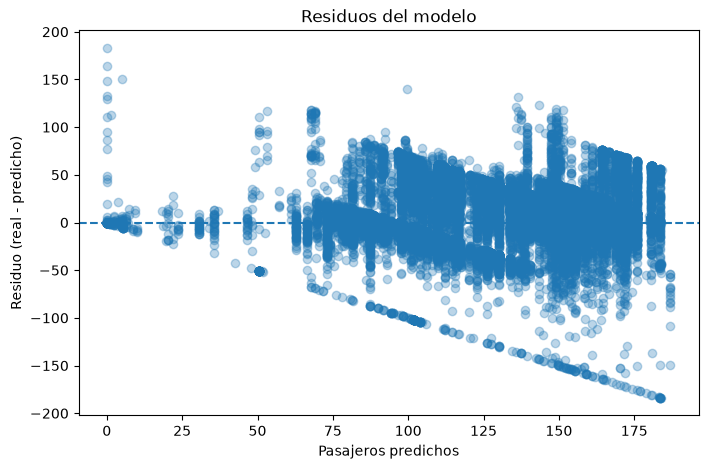

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(
    resultados_test["Pasajeros predichos"],
    resultados_test["Residuo"],
    alpha=0.3
)

plt.axhline(0, linestyle="--")

plt.xlabel("Pasajeros predichos")
plt.ylabel("Residuo (real - predicho)")
plt.title("Residuos del modelo")

plt.show()

### Interpretación del gráfico

Los residuos aparecen tanto por encima como por debajo de cero, aunque no están distribuidos de manera completamente pareja.

En algunas operaciones la diferencia entre el valor real y el estimado es bastante grande. Esto indica que el modelo funciona mejor en algunos casos que en otros.

Una posible explicación es que solo utiliza el aeropuerto de salida, el destino y la aerolínea. Por eso, distintas operaciones con esas mismas características pueden terminar recibiendo predicciones parecidas.

### Valores reales y predichos

Para ver de forma más clara cómo está funcionando el modelo, se comparan los valores reales de pasajeros con las predicciones hechas sobre el conjunto de prueba.

Cuanto más cerca quedan los puntos de la línea diagonal, más parecida es la predicción al valor real.

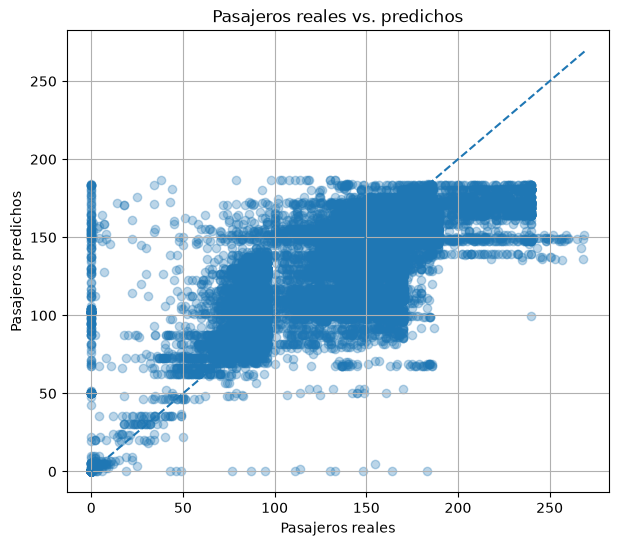

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    resultados_test["Pasajeros reales"],
    resultados_test["Pasajeros predichos"],
    alpha=0.3
)

plt.plot(
    [0, resultados_test["Pasajeros reales"].max()],
    [0, resultados_test["Pasajeros reales"].max()],
    linestyle="--"
)

plt.xlabel("Pasajeros reales")
plt.ylabel("Pasajeros predichos")
plt.title("Pasajeros reales vs. predichos")
plt.grid()

plt.show()

### Lectura del gráfico

En general, las predicciones siguen bastante bien la tendencia de los valores reales, aunque hay casos donde el modelo se aleja bastante.

Se nota que le cuesta más cuando la cantidad de pasajeros es muy baja o muy alta.

Esto tiene sentido con los resultados que vimos antes: el modelo logra captar parte del comportamiento de los datos, pero con solo aeropuerto de salida, destino y aerolínea todavía hay diferencias que no puede explicar del todo.

Antes de armar el ejemplo, se revisan algunas combinaciones frecuentes de aeropuerto, destino y aerolínea que aparecen en los datos utilizados para entrenar el modelo.

In [32]:
X_desarrollo.value_counts().head(10)

Aeropuerto  Origen / Destino  Aerolinea Nombre        
CBA         AER               AEROLINEAS ARGENTINAS SA    2542
AER         CBA               AEROLINEAS ARGENTINAS SA    2539
BAR         AER               AEROLINEAS ARGENTINAS SA    2205
AER         BAR               AEROLINEAS ARGENTINAS SA    2165
DOZ         AER               AEROLINEAS ARGENTINAS SA    2151
AER         DOZ               AEROLINEAS ARGENTINAS SA    2136
            IGU               AEROLINEAS ARGENTINAS SA    1741
IGU         AER               AEROLINEAS ARGENTINAS SA    1675
NEU         AER               AEROLINEAS ARGENTINAS SA    1450
AER         NEU               AEROLINEAS ARGENTINAS SA    1410
Name: count, dtype: int64

### Ejemplo de una nueva predicción

Para ver cómo se usaría el modelo con un caso nuevo, se toma como ejemplo un vuelo desde CBA hacia AER operado por Aerolíneas Argentinas.

Con esos datos, el modelo estima cuántos pasajeros podría tener esa operación.

In [33]:
nuevo_vuelo = pd.DataFrame({
    "Aeropuerto": ["CBA"],
    "Origen / Destino": ["AER"],
    "Aerolinea Nombre": ["AEROLINEAS ARGENTINAS SA"]
})

nuevo_vuelo_encoded = encoder_final.transform(nuevo_vuelo)

prediccion_nueva = modelo_final.predict(nuevo_vuelo_encoded)

print("Pasajeros estimados:", round(prediccion_nueva[0], 0))

Pasajeros estimados: 115.0


El modelo estima alrededor de 115 pasajeros para esta operación.

Este ejemplo sirve para mostrar cómo se puede usar el modelo con un vuelo nuevo a partir del aeropuerto de salida, el destino y la aerolínea.

## Conclusiones finales

El objetivo del proyecto fue estimar la cantidad de pasajeros de vuelos regulares de cabotaje utilizando información disponible antes de la salida del vuelo.

Se compararon una Regresión Lineal y un Árbol de Decisión, además de un baseline simple. El Árbol de Decisión obtuvo los mejores resultados en validación y se eligió como modelo final, utilizando un `max_depth` de 40.

En la prueba final con los datos de noviembre y diciembre, el modelo obtuvo un MAE de 23,77 pasajeros y un R² de 0,54. Esto muestra que logra captar parte de la variabilidad en la cantidad de pasajeros utilizando el aeropuerto de salida, el destino y la aerolínea.

El análisis de los residuos también mostró que el modelo tiende a subestimar levemente algunas predicciones y que todavía existen operaciones donde el error es más grande.

En general, los resultados muestran que estas tres variables aportan información útil para realizar una estimación, aunque el modelo todavía tiene margen de mejora incorporando otras variables que estén disponibles antes de la salida.

## Limitaciones y posibles mejoras

El modelo utiliza solamente el aeropuerto de salida, el destino y la aerolínea. Esto permite trabajar con información simple, pero también limita la capacidad de distinguir entre operaciones que comparten esas mismas características.

Además, la predicción se plantea 24 horas antes de la salida como un supuesto del proyecto. No se pudo confirmar que variables como la hora exacta del vuelo o la aeronave utilizada estén disponibles en ese momento, por lo que no se incluyeron en esta versión.

Otra limitación es que el análisis se realizó únicamente con datos de 2025. Por eso, los resultados muestran el comportamiento del modelo dentro de ese período y sería necesario probarlo con otros años para evaluar mejor su rendimiento en el tiempo.

También es importante aclarar que la variable `Pasajeros` representa la cantidad de pasajeros transportados registrada en cada operación, y no necesariamente la demanda total que podría haber tenido ese vuelo.

Como mejora futura se podrían incorporar nuevas variables que estén disponibles antes de la salida, siempre evitando utilizar información que pueda generar fuga de datos.